# LSTM + SA vs LSTM + TPE — lịch sử Copper bắt buộc + Spearman

Thêm CSV `dataset_9_commodities_daily.csv` vào Kaggle rồi Run All. Mặc định `quick`; chuyển `MODE='report'` cho báo cáo. Tự tìm CSV dưới `/kaggle/input`, hoặc đặt CSV_PATH cụ thể. Kết quả và ZIP lưu trong `/kaggle/working/results_tpe_sa_copper_history_v20/`.

Bản này chỉ so sánh hai phương pháp, với bốn mốc chia dữ liệu thô như `17-11-Copper-NonSA-Fair-Full-Protocol-V20.ipynb`: 80/20, 90/10, 92.5/7.5, 95/5. Trong phần trước test, giữ 10% cuối làm validation. Dùng chiến lược train expanding của V20; không thêm rolling/recency hoặc walk-forward GRU vào thí nghiệm hai phương pháp này.

Chọn biến, fit scalers và tuning độc lập ở từng tỷ lệ. Lưu nguyên mô hình trial thắng với trọng số early stopping tốt nhất, rồi đánh giá test sau khi khóa mọi cấu hình; **không refit train+validation**. Report vẫn giữ ngân sách 30 trials/phương pháp/seed, tối đa 30 epoch và patience=5 như bản SA–TPE trước; chỉ thay giao thức chia và đánh giá cuối. Quick chạy cả 4 tỷ lệ với 4 trials/phương pháp, 2 epoch, 1 seed.

Spearman xét |rho|>0.8 theo tiêu chí tương quan mạnh đã trao đổi, không ép tối đa 4 biến và không tự hạ ngưỡng. Lịch sử Copper luôn là đầu vào khi INCLUDE_COPPER_HISTORY=True; Spearman chỉ chọn biến bổ sung ngoài Copper. Nếu không có biến ngoài đạt ngưỡng, dùng Copper-only. Mọi đầu vào đều chỉ lấy ở các phiên quá khứ.

Đã xác thực cú pháp, logic chia như V20, lựa chọn biến không phụ thuộc dữ liệu tương lai, và ngân sách trial bằng kiểm thử riêng; chưa huấn luyện TensorFlow trên Kaggle khi bàn giao.


## 1. Mục tiêu và đầu vào Copper quá khứ

So sánh hai sampler SA/TPE tối ưu cùng LSTM hai lớp. Để dự báo Copper(t), mỗi mẫu chứa Copper(t-22),...,Copper(t-1), cộng các biến ngoài được Spearman chọn trên train ở đúng 22 phiên đó. Copper(t) là nhãn, không xuất hiện trong X. Đây là dự báo trực tiếp một bước; không chuyển sang residual prediction.

Kiến trúc: Input(22, số biến) → LSTM(u1, sequences=True) → LSTM(u2) → Dense(32, ReLU) → Dropout(0.2) → Dense(1, linear). Adam, MSE và batch 64. SA/TPE tìm hai số neuron [16,128] và learning rate log-uniform [1e-5,1e-2].

INCLUDE_COPPER_HISTORY=True bảo đảm Copper đứng đầu danh sách FEATURES, không phụ thuộc ngưỡng tương quan. Các biến còn lại phải có |Spearman lag 1|>0.8 trên train của từng tỷ lệ. Không có biến ngoài đạt ngưỡng thì dùng Copper-only, không tự hạ ngưỡng. Chỉ đặt cờ False nếu chủ động làm thí nghiệm không có lịch sử Copper; nếu khi đó không có biến ngoài đạt ngưỡng, notebook dừng.

Bản trước đã coi Copper là ứng viên Spearman và CSV hiện tại đã chọn Copper. Bản này đổi quy tắc để luôn giữ Copper khi bật cờ, không giả định thêm lịch sử Copper sẽ tự làm lỗi test giảm.


## 2. Giao thức chia như V20

| Nhãn train/test | Train thô | Validation | Test |
|---|---:|---:|---:|
| 80/20 | 72% | 8% | 20% |
| 90/10 | 81% | 9% | 10% |
| 92.5/7.5 | 83.25% | 9.25% | 7.5% |
| 95/5 | 85.5% | 9.5% | 5% |

Với n hàng đã làm sạch: test_start=int(n*ratio), val_start=int(test_start*0.9). Train targets t=LOOKBACK,...,val_start-1; validation t=val_start,...,test_start-1; test t=test_start,...,n-1. Vì cần 22 phiên lịch sử, số mẫu train ít hơn số hàng train 22. Không chia ngẫu nhiên.

Spearman và X/y scalers fit riêng trên train từng ratio. Hai phương pháp dùng cùng các biến, dữ liệu, kiến trúc, epoch tối đa và seed ở mỗi ratio. Spearman tính tương quan lag 1 trên train như bản trước, không dùng validation/test. Copper history được giữ cố định khi bật cờ; các ứng viên ngoài Copper phải có |rho|>0.8. Bộ biến được chốt một lần/ratio và dùng chung cho hai phương pháp, không chọn lại theo seed.

Tuning chỉ nhận train/validation; tất cả ratio/seed được khóa trước bước predict test. Mỗi trial có early stopping restore_best_weights=True. Khi gặp trial tốt hơn, lưu model với trọng số đó; sau tuning tải đúng model thắng để đánh giá test, không huấn luyện thêm. Đây là cách giữ train/validation riêng như V20. Cùng số trials chưa đồng nghĩa cùng thời gian tính toán.

Các khoảng test giữa bốn ratio có thể chồng lấn. So sánh SA/TPE trong cùng ratio và seed; không coi bốn test là bốn bộ dữ liệu độc lập. Việc thay ratio, biến hoặc ngưỡng sau khi xem test là vòng phát triển mới, không phải kiểm định độc lập.


In [1]:
# Giữ các thư viện đã có sẵn của Kaggle; chỉ cài những gói còn thiếu.
# Nếu cần cài, bật Internet. Nếu runtime yêu cầu restart sau cài, restart rồi Run All.
import importlib.util
import subprocess
import sys
requirements = {
    'numpy': 'numpy>=1.26,<3',
    'pandas': 'pandas>=2.1,<3',
    'sklearn': 'scikit-learn>=1.4,<2',
    'matplotlib': 'matplotlib>=3.8,<4',
    'tensorflow': 'tensorflow>=2.16,<2.21',
    'optuna': 'optuna>=4.2,<6',
}
missing = [requirement for module, requirement in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print('Cài thư viện còn thiếu:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
else:
    print('Đã có đủ thư viện; không cài lại TensorFlow hoặc NumPy.')

Đã có đủ thư viện; không cài lại TensorFlow hoặc NumPy.


In [2]:
import os
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import gc, sys, json, time, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import optuna
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display
try:
    tf.config.experimental.enable_op_determinism()
except AttributeError:
    pass
for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
optuna.logging.set_verbosity(optuna.logging.WARNING)
print('Python:', platform.python_version(), '| TensorFlow:', tf.__version__, '| Optuna:', optuna.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

Python: 3.13.16 | TensorFlow: 2.21.0 | Optuna: 5.0.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
# === CẤU HÌNH: chốt trước khi xem kết quả test ===
MODE = 'report'
CSV_PATH = '/kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv'
DATA_FILENAME = 'dataset_9_commodities_daily.csv'
# Chỉ dùng CSV của bạn; không tải Yahoo Finance.
FEATURES = None  # Được chốt bởi Spearman trên train, không sửa ở đây
INCLUDE_COPPER_HISTORY = True  # Bắt buộc giữ Copper quá khứ làm input khi True
SPEARMAN_THRESHOLD = 0.80
MAX_FEATURES = None  # None: không giới hạn số biến đạt ngưỡng
DROPOUT_RATE = 0.20
LOOKBACK = 22
RATIOS = [0.80, 0.90, 0.925, 0.95]
VAL_FRACTION_OF_DEVELOPMENT = 0.10
BATCH_SIZE = 64
PATIENCE = 5
MASE_LAG = 1                    # naive không mùa vụ, một phiên giao dịch
SA_T0, SA_TEND = 1.0, 0.01      # nhiệt độ tương đối; xem phần giải thích SA
SA_STEP = 0.20
SPACE = {
    'units_layer1': (16, 128),
    'units_layer2': (16, 128),
    'learning_rate': (1e-5, 1e-2),
}
assert MODE in ('quick', 'report')
N_TRIALS = 30 if MODE == 'report' else 4
MAX_EPOCHS = 30 if MODE == 'report' else 2
SEEDS = [42, 2024, 710] if MODE == 'report' else [42]
N_STARTUP = 10 if MODE == 'report' else 2
# Chỉ là điểm xuất phát chung trong miền của notebook; không lấy từ test.
INITIAL_PARAMS = dict(units_layer1=64, units_layer2=64, learning_rate=1e-3)
assert N_TRIALS > N_STARTUP >= 1
assert 0 < SA_TEND <= SA_T0 and 0 < SA_STEP <= 1
OUTPUT_ROOT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
RUN_DIR = OUTPUT_ROOT / 'results_tpe_sa_copper_history_v20' / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + '_' + MODE)
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Lưu kết quả:', RUN_DIR.resolve())
print(f'{MODE=}, {N_TRIALS=} mỗi phương pháp/seed, {MAX_EPOCHS=}, {SEEDS=}')
ROOT_RUN_DIR = RUN_DIR


Lưu kết quả: /kaggle/working/results_tpe_sa_copper_history_v20/20261118T121724200339Z_report
MODE='report', N_TRIALS=30 mỗi phương pháp/seed, MAX_EPOCHS=30, SEEDS=[42, 2024, 710]


## 3. Đọc CSV và kiểm tra dữ liệu

Mặc định dùng đúng `dataset_9_commodities_daily.csv` dưới `/kaggle/input`; có thể đặt CSV_PATH là đường dẫn đầy đủ. Chấp nhận tên Copper/WTI/Gold/Silver hoặc tên có tiền tố Price_. Tất cả cột ngoài Date được coi là biến giá ứng viên và phải là số. Bỏ hàng thiếu/không hữu hạn trong các cột này trước khi chia, thống kê số hàng bị bỏ; không backfill/interpolate. Ngày trùng hoặc không hợp lệ sẽ dừng để người dùng kiểm tra. Các cột phụ dạng chữ cần loại khỏi CSV trước khi chạy.

Toàn bộ bảng giá được giữ để chọn biến và lưu snapshot; những biến không được chọn không đi vào LSTM. Đơn vị giá phải đối chiếu nguồn CSV trước khi diễn giải sai số.

In [4]:
def clean_frame(frame):
    frame = frame.copy()
    frame.columns = [str(x).strip().lstrip('\ufeff') for x in frame.columns]
    aliases = {'Copper':'Price_Copper','WTI':'Price_WTI','Gold':'Price_Gold','Silver':'Price_Silver'}
    if frame.columns.duplicated().any() or any(a in frame.columns and b in frame.columns for a,b in aliases.items()):
        raise ValueError('Cột bị trùng hoặc nhập nhằng giữa tên gốc và Price_.')
    frame = frame.rename(columns=aliases)
    if not {'Date','Price_Copper'}.issubset(frame.columns):
        raise ValueError('CSV cần Date và Copper (hoặc Price_Copper).')
    frame['Date'] = pd.to_datetime(frame['Date'],errors='coerce',utc=True).dt.tz_convert(None).dt.normalize()
    if frame['Date'].isna().any() or frame['Date'].duplicated().any():
        raise ValueError('Date không hợp lệ hoặc trùng ngày. Hãy kiểm tra CSV.')
    for key in frame.columns.drop('Date'):
        frame[key] = pd.to_numeric(frame[key],errors='raise')
    initial_rows = len(frame)
    frame = frame.replace([np.inf,-np.inf],np.nan).dropna().sort_values('Date').reset_index(drop=True)
    print(f'Dòng nguồn={initial_rows}; bỏ thiếu/không hữu hạn={initial_rows-len(frame)}; dùng={len(frame)}')
    if len(frame)<LOOKBACK+100:
        raise ValueError('Cần ít nhất LOOKBACK+100 dòng hợp lệ.')
    return frame

def resolve_csv_path(csv_path, filename, input_root=Path('/kaggle/input')):
    if csv_path is not None:
        p = Path(csv_path).expanduser()
        if not p.is_file(): raise FileNotFoundError(p)
        return p
    found = sorted(p for p in input_root.rglob(filename) if p.is_file()) if input_root.is_dir() else []
    if len(found)!=1:
        raise FileNotFoundError(f'Cần đúng một {filename} dưới {input_root}; tìm được {found}. Đặt CSV_PATH cụ thể.')
    return found[0]

source_path = resolve_csv_path(CSV_PATH, DATA_FILENAME)
raw = pd.read_csv(source_path,encoding='utf-8-sig')
df = clean_frame(raw)
data_source = {'type':'csv','path':str(source_path),'input_sha256':hashlib.sha256(source_path.read_bytes()).hexdigest()}
snapshot = RUN_DIR/'dataset_snapshot.csv'
df.to_csv(snapshot,index=False,encoding='utf-8-sig')
data_source['snapshot_sha256'] = hashlib.sha256(snapshot.read_bytes()).hexdigest()
print('Nguồn:', source_path)
display(df.head())

Dòng nguồn=2710; bỏ thiếu/không hữu hạn=0; dùng=2710
Nguồn: /kaggle/input/datasets/thanhcong21206/ptdlkd-doan/dataset_9_commodities_daily.csv


,Date,Price_Copper,Aluminium,Nickel,Tin,Iron_Ore_62,Price_Silver,Price_Gold,Price_WTI,Brent
0,2016-01-13,1.9560,1462.5,8250.0,13305.0,40.42,14.156,1087.1,30.48,30.31
1,2016-01-14,1.9760,1483.0,8610.0,13260.0,40.59,13.748,1073.6,31.20,31.03
2,2016-01-15,1.9435,1473.0,8400.0,13205.0,40.79,13.896,1090.7,29.42,28.94
3,2016-01-19,1.9775,1481.0,8575.0,13225.0,41.32,14.121,1090.7,28.46,28.76
4,2016-01-20,1.9595,1469.0,8540.0,13390.0,41.19,14.160,1106.2,26.55,27.88


Ratio=0.8: features=['Price_Copper', 'Aluminium', 'Tin', 'Nickel']; train=1929, val=217, test=542
Input mỗi mẫu: 22 phiên × 4 biến; Copper history bắt buộc=True


,feature,rho_lag1,abs_rho,selected,selection_rule
0,Price_Copper,0.996861,0.996861,True,mandatory_copper_history
1,Aluminium,0.912210,0.912210,True,spearman_external_candidate
3,Tin,0.836207,0.836207,True,spearman_external_candidate
2,Nickel,0.829171,0.829171,True,spearman_external_candidate
4,Iron_Ore_62,0.747201,0.747201,False,spearman_external_candidate
7,Price_WTI,0.743007,0.743007,False,spearman_external_candidate
8,Brent,0.718254,0.718254,False,spearman_external_candidate
6,Price_Gold,0.673433,0.673433,False,spearman_external_candidate
5,Price_Silver,0.661060,0.661060,False,spearman_external_candidate


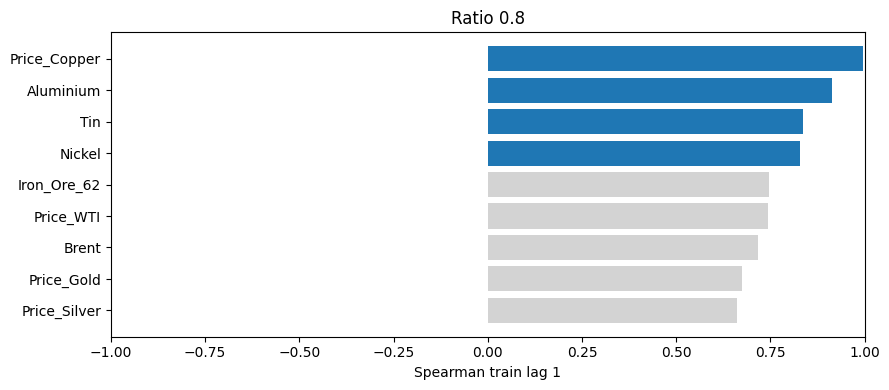

Ratio=0.9: features=['Price_Copper', 'Aluminium', 'Tin', 'Nickel']; train=2173, val=244, test=271
Input mỗi mẫu: 22 phiên × 4 biến; Copper history bắt buộc=True


,feature,rho_lag1,abs_rho,selected,selection_rule
0,Price_Copper,0.997141,0.997141,True,mandatory_copper_history
1,Aluminium,0.923735,0.923735,True,spearman_external_candidate
3,Tin,0.878332,0.878332,True,spearman_external_candidate
2,Nickel,0.814424,0.814424,True,spearman_external_candidate
7,Price_WTI,0.761666,0.761666,False,spearman_external_candidate
4,Iron_Ore_62,0.742547,0.742547,False,spearman_external_candidate
5,Price_Silver,0.736510,0.736510,False,spearman_external_candidate
6,Price_Gold,0.735404,0.735404,False,spearman_external_candidate
8,Brent,0.733120,0.733120,False,spearman_external_candidate


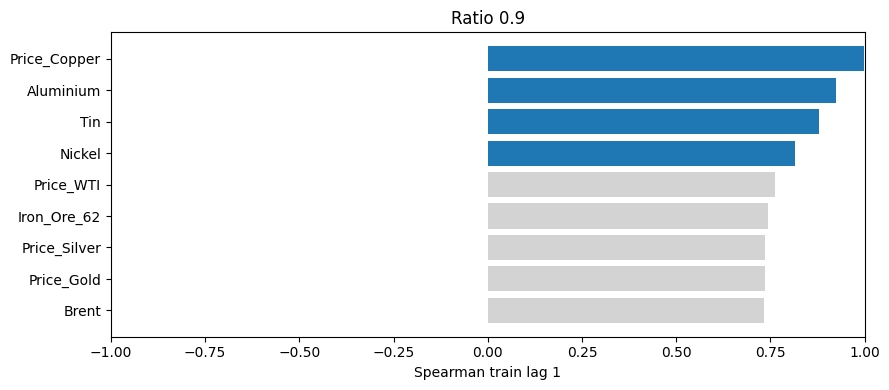

Ratio=0.925: features=['Price_Copper', 'Aluminium', 'Tin', 'Nickel']; train=2233, val=251, test=204
Input mỗi mẫu: 22 phiên × 4 biến; Copper history bắt buộc=True


,feature,rho_lag1,abs_rho,selected,selection_rule
0,Price_Copper,0.997137,0.997137,True,mandatory_copper_history
1,Aluminium,0.926220,0.926220,True,spearman_external_candidate
3,Tin,0.886244,0.886244,True,spearman_external_candidate
2,Nickel,0.803009,0.803009,True,spearman_external_candidate
7,Price_WTI,0.760602,0.760602,False,spearman_external_candidate
5,Price_Silver,0.748569,0.748569,False,spearman_external_candidate
6,Price_Gold,0.744280,0.744280,False,spearman_external_candidate
4,Iron_Ore_62,0.735932,0.735932,False,spearman_external_candidate
8,Brent,0.728994,0.728994,False,spearman_external_candidate


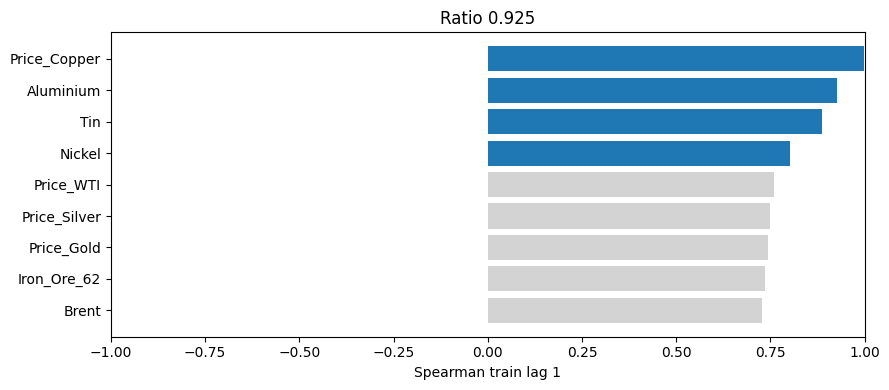

Ratio=0.95: features=['Price_Copper', 'Aluminium', 'Tin']; train=2294, val=258, test=136
Input mỗi mẫu: 22 phiên × 3 biến; Copper history bắt buộc=True


,feature,rho_lag1,abs_rho,selected,selection_rule
0,Price_Copper,0.997203,0.997203,True,mandatory_copper_history
1,Aluminium,0.926439,0.926439,True,spearman_external_candidate
3,Tin,0.891358,0.891358,True,spearman_external_candidate
2,Nickel,0.781398,0.781398,False,spearman_external_candidate
5,Price_Silver,0.766832,0.766832,False,spearman_external_candidate
6,Price_Gold,0.762510,0.762510,False,spearman_external_candidate
7,Price_WTI,0.743123,0.743123,False,spearman_external_candidate
4,Iron_Ore_62,0.718909,0.718909,False,spearman_external_candidate
8,Brent,0.706687,0.706687,False,spearman_external_candidate


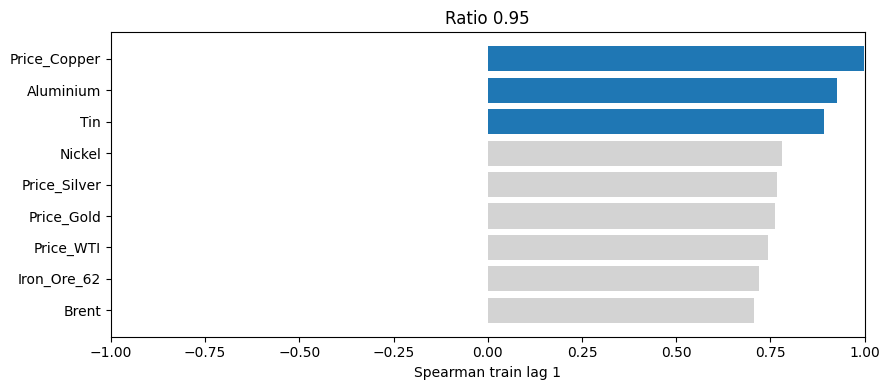

,ratio,segment,samples,first_target,last_target
0,0.800,train,1929,2016-02-16 00:00:00,2023-12-06 00:00:00
1,0.800,validation,217,2023-12-07 00:00:00,2024-10-04 00:00:00
2,0.800,test,542,2024-10-07 00:00:00,2026-11-13 00:00:00
3,0.900,train,2173,2016-02-16 00:00:00,2024-11-12 00:00:00
4,0.900,validation,244,2024-11-13 00:00:00,2025-10-28 00:00:00
5,0.900,test,271,2025-10-29 00:00:00,2026-11-13 00:00:00
6,0.925,train,2233,2016-02-16 00:00:00,2025-02-10 00:00:00
7,0.925,validation,251,2025-02-11 00:00:00,2026-01-29 00:00:00
8,0.925,test,204,2026-01-30 00:00:00,2026-11-13 00:00:00
9,0.950,train,2294,2016-02-16 00:00:00,2025-05-08 00:00:00


Ví dụ input trước ngày target:


,ratio,n_features,lookback,first_input_date,last_input_date,target_date,copper_history
0,0.800,4,22,2023-11-07 00:00:00,2023-12-06 00:00:00,2023-12-07 00:00:00,True
1,0.900,4,22,2024-10-14 00:00:00,2024-11-12 00:00:00,2024-11-13 00:00:00,True
2,0.925,4,22,2025-01-09 00:00:00,2025-02-10 00:00:00,2025-02-11 00:00:00,True
3,0.950,3,22,2025-04-08 00:00:00,2025-05-08 00:00:00,2025-05-09 00:00:00,True


In [5]:
def split_positions(frame, ratio):
    n=len(frame)
    test_start=int(n*ratio)
    val_start=int(test_start*(1-VAL_FRACTION_OF_DEVELOPMENT))
    if not LOOKBACK<val_start<test_start<n: raise ValueError('Không đủ dữ liệu cho cách chia.')
    return val_start,test_start


def select_features(frame, ratio):
    val_start,test_start=split_positions(frame,ratio)
    targets=np.arange(LOOKBACK,val_start)
    candidates=[k for k in frame.columns if k!='Date' and (INCLUDE_COPPER_HISTORY or k!='Price_Copper')]
    rows=[]
    for key in candidates:
        x=frame[key].iloc[targets-1].reset_index(drop=True)
        y=frame['Price_Copper'].iloc[targets].reset_index(drop=True)
        rho=float(x.corr(y,method='spearman')) if x.nunique()>1 and y.nunique()>1 else float('nan')
        rows.append(dict(feature=key,rho_lag1=rho,abs_rho=abs(rho)))
    ranking=pd.DataFrame(rows).sort_values(['abs_rho','feature'],ascending=[False,True],na_position='last')
    chosen=ranking.loc[(ranking.feature!='Price_Copper') & (ranking.abs_rho>SPEARMAN_THRESHOLD),'feature']
    if MAX_FEATURES is not None: chosen=chosen.head(MAX_FEATURES)
    chosen=chosen.tolist()
    if INCLUDE_COPPER_HISTORY:
        chosen=['Price_Copper']+chosen
    if not chosen: raise ValueError(f'Ratio {ratio}: không có biến đạt |rho|>{SPEARMAN_THRESHOLD}. Không tự hạ ngưỡng theo test.')
    ranking['selected']=ranking.feature.isin(chosen)
    ranking['selection_rule']=np.where((ranking.feature=='Price_Copper') & INCLUDE_COPPER_HISTORY,
                                      'mandatory_copper_history','spearman_external_candidate')
    return chosen,ranking


def prepare_data(frame, ratio, features, include_test=False):
    val_start,test_start=split_positions(frame,ratio)
    xsc=MinMaxScaler().fit(frame[features].iloc[:val_start].to_numpy())
    ysc=MinMaxScaler().fit(frame[['Price_Copper']].iloc[:val_start].to_numpy())
    visible=frame if include_test else frame.iloc[:test_start]
    x=xsc.transform(visible[features].to_numpy()).astype(np.float32)
    y=ysc.transform(visible[['Price_Copper']].to_numpy()).ravel().astype(np.float32)
    def block(start,end):
        idx=np.arange(start,end)
        X=np.stack([x[t-LOOKBACK:t] for t in idx])
        if INCLUDE_COPPER_HISTORY:
            assert features[0]=='Price_Copper'
            assert np.allclose(X[:,-1,0],y[idx-1],atol=2e-6,rtol=1e-6), 'Copper input phải khớp giá t-1, không phải t.'
        return X,y[idx]
    Xtr,ytr=block(LOOKBACK,val_start)
    Xva,yva=block(val_start,test_start)
    train_prices=frame.Price_Copper.iloc[:val_start].to_numpy()
    mase_scale=float(np.mean(np.abs(np.diff(train_prices))))
    if not np.isfinite(mase_scale) or mase_scale<=0: raise ValueError('Mẫu số MASE train không hợp lệ.')
    result=dict(X_train=Xtr,y_train=ytr,X_val=Xva,y_val=yva,scaler=ysc,x_scaler=xsc,
                mase_scale=mase_scale,train_end=val_start,test_start=test_start,ratio=ratio,features=list(features))
    if include_test:
        Xte,yte=block(test_start,len(frame))
        result.update(X_test=Xte,y_test=yte,test_dates=frame.Date.iloc[test_start:].to_numpy(),
                      y_test_original=frame.Price_Copper.iloc[test_start:].to_numpy())
    return result

split_contexts={}; split_audit=[]
for ratio in RATIOS:
    folder=ROOT_RUN_DIR/f'ratio_{ratio:.3f}'
    folder.mkdir(parents=True,exist_ok=True)
    features,ranking=select_features(df,ratio)
    ctx=prepare_data(df,ratio,features,include_test=False)
    assert 'X_test' not in ctx and 'y_test_original' not in ctx
    ranking.to_csv(folder/'spearman_feature_selection.csv',index=False)
    (folder/'selected_features.json').write_text(json.dumps(features,ensure_ascii=False,indent=2),encoding='utf-8')
    split_contexts[ratio]=dict(folder=folder,features=features,ranking=ranking,context=ctx)
    a,b=ctx['train_end'],ctx['test_start']
    for segment,start,end in [('train',LOOKBACK,a),('validation',a,b),('test',b,len(df))]:
        split_audit.append(dict(ratio=ratio,segment=segment,samples=end-start,
                                first_target=str(df.Date.iloc[start]),last_target=str(df.Date.iloc[end-1])))
    print(f'Ratio={ratio}: features={features}; train={len(ctx["y_train"])}, val={len(ctx["y_val"])}, test={len(df)-b}',flush=True)
    print(f'Input mỗi mẫu: {LOOKBACK} phiên × {len(features)} biến; Copper history bắt buộc={INCLUDE_COPPER_HISTORY}',flush=True)
    display(ranking)
    fig,ax=plt.subplots(figsize=(9,4))
    ax.barh(ranking.feature,ranking.rho_lag1,color=['tab:blue' if x else 'lightgray' for x in ranking.selected])
    ax.set(xlim=(-1,1),xlabel='Spearman train lag 1',title=f'Ratio {ratio}')
    ax.invert_yaxis(); fig.tight_layout(); fig.savefig(folder/'spearman_selection.png',dpi=150); plt.show()
split_audit_df=pd.DataFrame(split_audit)
split_audit_df.to_csv(ROOT_RUN_DIR/'data_split_summary.csv',index=False)
display(split_audit_df)

# Hiển thị ví dụ đầu vào và ngày cần dự báo, không đưa giá target vào bảng input.
input_audit=[]
for ratio,item in split_contexts.items():
    features=item['features']; a,b=split_positions(df,ratio)
    sample=df[['Date']+features].iloc[a-LOOKBACK:a].copy()
    assert sample.Date.max()<df.Date.iloc[a]
    sample.to_csv(item['folder']/'example_validation_input_22_sessions.csv',index=False)
    input_audit.append(dict(ratio=ratio,n_features=len(features),lookback=LOOKBACK,
                            first_input_date=str(sample.Date.iloc[0]),last_input_date=str(sample.Date.iloc[-1]),
                            target_date=str(df.Date.iloc[a]),copper_history=INCLUDE_COPPER_HISTORY))
input_audit_df=pd.DataFrame(input_audit)
input_audit_df.to_csv(ROOT_RUN_DIR/'input_history_audit.csv',index=False)
print('Ví dụ input trước ngày target:')
display(input_audit_df)


## 5. LSTM và objective dùng chung

Mỗi trial chỉ fit train và đánh giá validation, chọn epoch có validation MSE nhỏ nhất. Không dùng test trong objective. Thang chuẩn hóa dùng riêng X và y, fit trên train; giá validation/test được phép vượt [0,1]. Seed huấn luyện cố định trong từng lần lặp và dùng chung giữa hai phương pháp. Sai số không hữu hạn được ghi failed và vẫn tính vào ngân sách.

In [6]:
class NonFiniteTraining(RuntimeError):
    def __init__(self, message, epochs_run):
        super().__init__(message)
        self.epochs_run = int(epochs_run)

def build_model(p, seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(int(seed))
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(LOOKBACK, len(FEATURES))),
        tf.keras.layers.LSTM(int(p['units_layer1']), return_sequences=True),
        tf.keras.layers.LSTM(int(p['units_layer2'])),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dropout(DROPOUT_RATE),
        tf.keras.layers.Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(p['learning_rate'])), loss='mse')
    return model

def evaluate_config(p, train_seed):
    global ACTIVE_BEST_LOSS
    start = time.perf_counter()
    model = None
    try:
        model = build_model(p, train_seed)
        history = model.fit(D['X_train'], D['y_train'],
                            validation_data=(D['X_val'], D['y_val']),
                            epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, shuffle=False,
                            callbacks=[tf.keras.callbacks.EarlyStopping(
                                monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
                                tf.keras.callbacks.TerminateOnNaN()], verbose=2 if MODE=='quick' else 0)
        losses = np.asarray(history.history['val_loss'], dtype=float)
        train_losses = np.asarray(history.history['loss'], dtype=float)
        if not np.all(np.isfinite(losses)) or not np.all(np.isfinite(train_losses)):
            raise NonFiniteTraining('Loss không hữu hạn trong quá trình fit', len(losses))
        best_epoch = int(np.argmin(losses)) + 1
        if float(losses[best_epoch-1]) < ACTIVE_BEST_LOSS:
            model.save(ACTIVE_MODEL_PATH)
            ACTIVE_BEST_LOSS = float(losses[best_epoch-1])
        return dict(val_mse=float(losses[best_epoch-1]), best_epoch=best_epoch,
                    epochs_run=len(losses), trial_seconds=time.perf_counter()-start, status='complete')
    finally:
        del model
        tf.keras.backend.clear_session()
        gc.collect()

def safe_evaluate(p, seed):
    start = time.perf_counter()
    try:
        return evaluate_config(p, seed)
    except NonFiniteTraining as exc:
        return dict(val_mse=float('inf'), best_epoch=0, epochs_run=exc.epochs_run,
                    trial_seconds=time.perf_counter()-start, status='failed', error=str(exc))

def suggest_params(trial):
    return dict(units_layer1=trial.suggest_int('units_layer1', *SPACE['units_layer1']),
                units_layer2=trial.suggest_int('units_layer2', *SPACE['units_layer2']),
                learning_rate=trial.suggest_float('learning_rate', *SPACE['learning_rate'], log=True))

### SA dùng trong thí nghiệm

Đưa ba tham số về [0,1], riêng learning rate dùng log10; đề xuất bằng nhiễu Gaussian rồi phản xạ tại biên, làm tròn hai số neuron. Nhiệt độ đi từ 1 đến 0.01 theo lịch hình học trong **đúng N_TRIALS** lần đánh giá. Độ rộng bước là `SA_STEP * sqrt(T / SA_T0)`.

Để nhiệt độ không phụ thuộc đơn vị MSE, dùng năng lượng `E = validation_MSE / max(initial_validation_MSE, 1e-12)`. Với bước xấu, xác suất chấp nhận là `exp(-(E_new-E_current)/T)`. Nếu khởi đầu thất bại, dùng trial hữu hạn đầu tiên để đặt thang năng lượng. Thang này chỉ lấy từ validation, không từ test. Cấu hình bị từ chối vẫn được ghi log và tính ngân sách; không dùng cache để bỏ qua huấn luyện.

Hàm đề xuất, thang năng lượng và lịch nhiệt này là lựa chọn thiết kế cho bản đối chiếu, không khẳng định trùng mã SA gốc của tác giả.

In [7]:
PARAM_KEYS = list(SPACE)

def encode(p):
    out = []
    for key in PARAM_KEYS:
        lo, hi = SPACE[key]
        v = p[key]
        if key == 'learning_rate':
            lo, hi, v = np.log10(lo), np.log10(hi), np.log10(v)
        out.append((v-lo)/(hi-lo))
    return np.array(out, dtype=float)

def decode(z):
    p = {}
    for key, v in zip(PARAM_KEYS, z):
        lo, hi = SPACE[key]
        if key == 'learning_rate':
            value = 10 ** (np.log10(lo) + float(v)*(np.log10(hi)-np.log10(lo)))
        else:
            value = lo + float(v)*(hi-lo)
        p[key] = int(np.rint(value)) if key.startswith('units_') else float(value)
        p[key] = max(lo, min(hi, p[key]))
    return p

def reflect(z):
    return 1 - np.abs(np.mod(z, 2) - 1)

def metropolis(delta, temperature, rng):
    return delta <= 0 or rng.random() < np.exp(-delta / temperature)

def run_search(method, seed):
    start = time.perf_counter()
    rows = []
    def record(p, result, extra=None):
        row = dict(method=method, seed=int(seed), trial=len(rows)+1, **p, **result,
                   elapsed_seconds=time.perf_counter()-start)
        row.update(extra or {})
        rows.append(row)
        pd.DataFrame(rows).to_csv(RUN_DIR / f'trials_{method}_{seed}.csv', index=False)
        print(f"{method} seed={seed} trial={row['trial']}/{N_TRIALS}: val_MSE={row['val_mse']:.7g}", flush=True)

    if method == 'TPE':
        sampler = optuna.samplers.TPESampler(seed=int(seed), n_startup_trials=N_STARTUP,
                                            multivariate=False)
        study = optuna.create_study(direction='minimize', sampler=sampler,
                                   pruner=optuna.pruners.NopPruner())
        study.enqueue_trial(INITIAL_PARAMS.copy())
        def objective(trial):
            p = suggest_params(trial)
            result = safe_evaluate(p, seed)
            record(p, result)
            return result['val_mse']
        study.optimize(objective, n_trials=N_TRIALS, n_jobs=1)
    elif method == 'SA':
        rng = np.random.default_rng(int(seed))
        current_p = INITIAL_PARAMS.copy()
        current = safe_evaluate(current_p, seed)
        scale = max(current['val_mse'], 1e-12) if np.isfinite(current['val_mse']) else None
        record(current_p, current, dict(temperature=SA_T0, accepted=True, current_val_mse=current['val_mse']))
        for i in range(1, N_TRIALS):
            temperature = SA_T0 * (SA_TEND/SA_T0) ** (i/(N_TRIALS-1))
            proposal_z = reflect(encode(current_p) + rng.normal(0, SA_STEP*np.sqrt(temperature/SA_T0), len(PARAM_KEYS)))
            proposal_p = decode(proposal_z)
            result = safe_evaluate(proposal_p, seed)
            accepted = False
            if np.isfinite(result['val_mse']):
                if scale is None:
                    scale = max(result['val_mse'], 1e-12)
                delta = (result['val_mse']-current['val_mse']) / scale
                accepted = metropolis(delta, temperature, rng)
            if accepted:
                current_p, current = proposal_p, result
            record(proposal_p, result, dict(temperature=temperature, accepted=bool(accepted),
                                           current_val_mse=current['val_mse']))
    else:
        raise ValueError(method)
    elapsed = time.perf_counter()-start
    log = pd.DataFrame(rows)
    assert len(log) == N_TRIALS
    valid = log[np.isfinite(log.val_mse)]
    if valid.empty:
        raise RuntimeError(f'{method} seed={seed}: không có cấu hình hợp lệ; xem log.')
    best = valid.loc[valid.val_mse.idxmin()]
    best_params = {key: (int(best[key]) if key.startswith('units_') else float(best[key])) for key in PARAM_KEYS}
    return log, dict(method=method, seed=int(seed), best_params=best_params,
                     best_val_mse=float(best.val_mse), best_epoch=int(best.best_epoch),
                     n_trials=len(log), n_success=int((log.status=='complete').sum()),
                     total_epochs=int(log.epochs_run.sum()), search_seconds=float(elapsed))

In [8]:
# Lưu dấu vết cấu hình và môi trường trước khi tuning.
config = {k:globals()[k] for k in ['MODE','LOOKBACK','RATIOS',
          'VAL_FRACTION_OF_DEVELOPMENT','BATCH_SIZE','PATIENCE','MASE_LAG',
          'N_TRIALS','MAX_EPOCHS','SEEDS','N_STARTUP','INITIAL_PARAMS','SPACE',
          'SA_T0','SA_TEND','SA_STEP','DROPOUT_RATE','INCLUDE_COPPER_HISTORY','SPEARMAN_THRESHOLD','MAX_FEATURES']}
config.update(data_source=data_source, created_utc=datetime.now(timezone.utc).isoformat(),
              tensorflow_devices=[str(x) for x in tf.config.list_physical_devices()],
              python=sys.version, versions={p:metadata.version(p) for p in
              ['tensorflow','optuna','numpy','pandas','scikit-learn','matplotlib']})
(RUN_DIR/'experiment_config.json').write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding='utf-8')


1580

In [9]:
# Giai đoạn 1: tune mọi ratio/seed trước khi predict bất kỳ test nào.
all_logs,selected=[],[]
for ratio in RATIOS:
    item=split_contexts[ratio]
    RUN_DIR=item['folder']; FEATURES=item['features']; D=item['context']
    for run_idx,seed in enumerate(SEEDS):
        order=['TPE','SA'] if run_idx%2==0 else ['SA','TPE']
        for method in order:
            ACTIVE_MODEL_PATH=RUN_DIR/f'best_trial_{method}_{seed}.keras'
            ACTIVE_BEST_LOSS=float('inf')
            print(f'BEGIN ratio={ratio} {method} seed={seed}',flush=True)
            log,best=run_search(method,seed)
            if not ACTIVE_MODEL_PATH.is_file(): raise RuntimeError('Thiếu checkpoint trial tốt nhất.')
            log['ratio']=ratio
            best.update(ratio=ratio,features=list(FEATURES),model_path=str(ACTIVE_MODEL_PATH))
            all_logs.append(log); selected.append(best)
trials_df=pd.concat(all_logs,ignore_index=True)
trials_df.to_csv(ROOT_RUN_DIR/'all_trials.csv',index=False)
(ROOT_RUN_DIR/'selected_configs.json').write_text(json.dumps(selected,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame([{k:v for k,v in s.items() if k not in ['best_params','features']} for s in selected]))
RUN_DIR=ROOT_RUN_DIR


BEGIN ratio=0.8 TPE seed=42


E0000 00:00:1795004248.975276      24 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


TPE seed=42 trial=1/30: val_MSE=0.001958282


E0000 00:00:1795004259.569452      24 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


TPE seed=42 trial=2/30: val_MSE=0.003308937


E0000 00:00:1795004266.158135      24 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


... (1,432 outputs left out)

SA seed=710 trial=29/30: val_MSE=0.005367639


E0000 00:00:1795018629.880785      24 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


SA seed=710 trial=30/30: val_MSE=0.003812147


,method,seed,best_val_mse,best_epoch,n_trials,n_success,total_epochs,search_seconds,ratio,model_path
0,TPE,42,0.001302,18,30,30,517,270.826518,0.800,/kaggle/working/results_tpe_sa_copper_history_...
1,SA,42,0.001557,30,30,30,550,309.761188,0.800,/kaggle/working/results_tpe_sa_copper_history_...
2,SA,2024,0.001529,16,30,30,475,308.870848,0.800,/kaggle/working/results_tpe_sa_copper_history_...
3,TPE,2024,0.001271,26,30,30,548,358.041030,0.800,/kaggle/working/results_tpe_sa_copper_history_...
4,TPE,710,0.001044,29,30,30,698,439.107571,0.800,/kaggle/working/results_tpe_sa_copper_history_...
5,SA,710,0.002159,27,30,30,466,391.582039,0.800,/kaggle/working/results_tpe_sa_copper_history_...
6,TPE,42,0.003763,23,30,30,529,447.212776,0.900,/kaggle/working/results_tpe_sa_copper_history_...
7,SA,42,0.004213,17,30,30,312,387.891858,0.900,/kaggle/working/results_tpe_sa_copper_history_...
8,SA,2024,0.004011,24,30,30,466,476.151305,0.900,/kaggle/working/results_tpe_sa_copper_history_...
9,TPE,2024,0.003561,29,30,30,598,544.846400,0.900,/kaggle/working/results_tpe_sa_copper_history_...


## 6. Đánh giá test bằng model trial thắng

Không refit và không gộp train+validation. Tải đúng checkpoint có validation MSE tốt nhất của mỗi phương pháp/seed/ratio; checkpoint đã restore trọng số epoch tốt nhất. Xác nhận validation MSE của checkpoint khớp log rồi mới predict test. Không dùng test để chọn biến, epoch hay tham số.


In [10]:
def metrics(y_true, y_pred, mase_scale):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    if y_true.shape != y_pred.shape or not np.all(np.isfinite(y_pred)):
        raise ValueError('Dự đoán sai kích thước hoặc không hữu hạn.')
    error = y_true-y_pred
    mae = float(np.mean(np.abs(error)))
    return dict(MAE=mae, RMSE=float(np.sqrt(np.mean(error**2))), MASE=mae/mase_scale)

def inverse_target(y_scaled):
    return (np.asarray(y_scaled).reshape(-1) - D['scaler'].min_[0]) / D['scaler'].scale_[0]

results,predictions=[],[]
for s in selected:
    ratio=s['ratio']; FEATURES=s['features']; folder=split_contexts[ratio]['folder']
    D=prepare_data(df,ratio,FEATURES,include_test=True)
    model=tf.keras.models.load_model(s['model_path'])
    val_pred=model.predict(D['X_val'],batch_size=BATCH_SIZE,verbose=0).ravel()
    restored_val_mse=float(np.mean((val_pred.astype(float)-D['y_val'].astype(float))**2))
    if not np.isclose(restored_val_mse,s['best_val_mse'],rtol=1e-3,atol=1e-7):
        raise RuntimeError(f'Checkpoint validation MSE khác log: {restored_val_mse} vs {s["best_val_mse"]}')
    start=time.perf_counter()
    pred=inverse_target(model.predict(D['X_test'],batch_size=BATCH_SIZE,verbose=0))
    m=metrics(D['y_test_original'],pred,D['mase_scale'])
    row={k:v for k,v in s.items() if k not in ['best_params','model_path','features']}
    row.update(m,test_mse=float(np.mean((D['y_test_original']-pred)**2)),
               restored_val_mse=restored_val_mse,test_predict_seconds=time.perf_counter()-start)
    results.append(row)
    predictions.append(pd.DataFrame(dict(Date=D['test_dates'],Actual=D['y_test_original'],Predicted=pred,
                                        method=s['method'],seed=s['seed'],ratio=ratio)))
    pd.DataFrame(results).to_csv(ROOT_RUN_DIR/'metrics_by_run.csv',index=False)
    np.savez(folder/'train_scalers.npz',x_scale=D['x_scaler'].scale_,x_offset=D['x_scaler'].min_,
             y_scale=D['scaler'].scale_,y_offset=D['scaler'].min_,features=np.array(FEATURES))
    print(f'TEST ratio={ratio} {s["method"]} seed={s["seed"]}: MAE={m["MAE"]:.6g}, RMSE={m["RMSE"]:.6g}',flush=True)
    del model; tf.keras.backend.clear_session(); gc.collect()
results_df=pd.DataFrame(results)
predictions_df=pd.concat(predictions,ignore_index=True)
predictions_df.to_csv(ROOT_RUN_DIR/'test_predictions.csv',index=False)
display(results_df)


E0000 00:00:1795018658.893839      24 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


TEST ratio=0.8 TPE seed=42: MAE=0.449535, RMSE=0.578893


E0000 00:00:1795018674.267673      24 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


TEST ratio=0.8 SA seed=42: MAE=0.253601, RMSE=0.329453


E0000 00:00:1795018689.614548      24 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


TEST ratio=0.8 SA seed=2024: MAE=0.244074, RMSE=0.314175


... (39 outputs left out)

TEST ratio=0.95 TPE seed=710: MAE=0.179914, RMSE=0.211472


E0000 00:00:1795019008.751062      24 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


TEST ratio=0.95 SA seed=710: MAE=0.170211, RMSE=0.203586


,method,seed,best_val_mse,best_epoch,n_trials,n_success,total_epochs,search_seconds,ratio,MAE,RMSE,MASE,test_mse,restored_val_mse,test_predict_seconds
0,TPE,42,0.001302,18,30,30,517,270.826518,0.800,0.449535,0.578893,13.663639,0.335117,0.001302,0.144249
1,SA,42,0.001557,30,30,30,550,309.761188,0.800,0.253601,0.329453,7.708227,0.108539,0.001557,0.139632
2,SA,2024,0.001529,16,30,30,475,308.870848,0.800,0.244074,0.314175,7.418638,0.098706,0.001529,0.136967
3,TPE,2024,0.001271,26,30,30,548,358.041030,0.800,0.615510,0.805296,18.708445,0.648502,0.001271,0.133414
4,TPE,710,0.001044,29,30,30,698,439.107571,0.800,0.441661,0.585818,13.424315,0.343183,0.001044,0.132751
5,SA,710,0.002159,27,30,30,466,391.582039,0.800,0.301775,0.382432,9.172452,0.146254,0.002159,0.131281
6,TPE,42,0.003763,23,30,30,529,447.212776,0.900,0.347229,0.394429,10.120553,0.155574,0.003763,0.114615
7,SA,42,0.004213,17,30,30,312,387.891858,0.900,0.430636,0.478465,12.551587,0.228928,0.004213,0.120199
8,SA,2024,0.004011,24,30,30,466,476.151305,0.900,0.358192,0.409082,10.440092,0.167348,0.004011,0.119403
9,TPE,2024,0.003561,29,30,30,598,544.846400,0.900,0.142853,0.177608,4.163668,0.031544,0.003561,0.120390


In [11]:
summary=results_df.groupby(['ratio','method'])[['best_val_mse','test_mse','MAE','RMSE','MASE','search_seconds','n_trials','total_epochs']].agg(['mean','std'])
summary.to_csv(ROOT_RUN_DIR/'summary_mean_std.csv')
display(summary)
paired=results_df.pivot(index=['ratio','seed'],columns='method',values=['best_val_mse','MAE','RMSE','MASE','search_seconds'])
paired_deltas=pd.DataFrame({f'TPE_minus_SA_{metric}':paired[metric]['TPE']-paired[metric]['SA']
                           for metric in ['best_val_mse','MAE','RMSE','MASE','search_seconds']})
paired_deltas.to_csv(ROOT_RUN_DIR/'paired_differences.csv')
print('Chênh lệch TPE − SA theo ratio/seed: số âm nghĩa là TPE có trị số thấp hơn.')
display(paired_deltas)
if len(SEEDS)<2: print('Quick chỉ một seed: std=NaN, chưa kết luận độ ổn định.')


best_val_mse            test_mse                 MAE            \
                     mean       std      mean       std      mean       std   
ratio method                                                                  
0.800 SA         0.001748  0.000356  0.117833  0.025100  0.266483  0.030932   
      TPE        0.001205  0.000141  0.442267  0.178650  0.502235  0.098177   
0.900 SA         0.004176  0.000151  0.142843  0.100601  0.310912  0.149097   
      TPE        0.003294  0.000646  0.136187  0.096422  0.305132  0.145860   
0.925 SA         0.004184  0.000694  0.081265  0.077542  0.229575  0.124708   
      TPE        0.003999  0.000591  0.035780  0.002760  0.154859  0.008635   
0.950 SA         0.003538  0.000241  0.089508  0.041786  0.265083  0.082362   
      TPE        0.003418  0.000357  0.063471  0.031503  0.216219  0.062693   

                  RMSE                 MASE           search_seconds  \
                  mean       std       mean       std           mean   
ratio method                                                           
0.800 SA      0.342020  0.035822   8.099773  0.940184     336.738025   
      TPE     0.656669  0.128762  15.265466  2.984107     355.991706   
0.900 SA      0.355713  0.156420   9.062030  4.345674     478.574276   
      TPE     0.347538  0.152010   8.893554  4.251327     509.818542   
0.925 SA      0.265001  0.128681   6.684817  3.631284     719.630457   
      TPE     0.189063  0.007279   4.509215  0.251431     695.180420   
0.950 SA      0.292469  0.077170   7.478860  2.323699     856.550401   
      TPE     0.247193  0.059584   6.100235  1.768779     851.632845   

                        n_trials      total_epochs              
                    std     mean  std         mean         std  
ratio method                                                    
0.800 SA      47.498395     30.0  0.0   497.000000   46.119410  
      TPE     84.159242     30.0  0.0   587.666667   96.800482  
0.900 SA      91.917857     30.0  0.0   435.000000  110.801625  
      TPE     54.345993     30.0  0.0   545.666667   46.306947  
0.925 SA      55.574497     30.0  0.0   604.333333   61.435603  
      TPE     62.981172     30.0  0.0   556.000000   38.118237  
0.950 SA      55.202304     30.0  0.0   544.666667   12.055428  
      TPE     63.388488     30.0  0.0   554.666667   12.662280

Chênh lệch TPE − SA theo ratio/seed: số âm nghĩa là TPE có trị số thấp hơn.


TPE_minus_SA_best_val_mse  TPE_minus_SA_MAE  TPE_minus_SA_RMSE  \
ratio seed                                                                   
0.800 42                    -0.000255          0.195934           0.249440   
      710                   -0.001116          0.139887           0.203386   
      2024                  -0.000258          0.371436           0.491122   
0.900 42                    -0.000449         -0.083407          -0.084036   
      710                   -0.001748          0.281406           0.290984   
      2024                  -0.000449         -0.215340          -0.231474   
0.925 42                    -0.001426         -0.220083          -0.224832   
      710                    0.000534         -0.000143           0.001070   
      2024                   0.000337         -0.003923          -0.004053   
0.950 42                     0.000310         -0.029653          -0.026428   
      710                   -0.000803          0.009702           0.007885   
      2024                   0.000133         -0.126642          -0.117283   

            TPE_minus_SA_MASE  TPE_minus_SA_search_seconds  
ratio seed                                                  
0.800 42             5.955411                   -38.934670  
      710            4.251862                    47.525532  
      2024          11.289806                    49.170182  
0.900 42            -2.431034                    59.320918  
      710            8.202027                   -34.283213  
      2024          -6.276424                    68.695094  
0.925 42            -6.408415                   -70.492211  
      710           -0.004168                   -29.434470  
      2024          -0.114223                    26.576568  
0.950 42            -0.836615                   -35.475181  
      710            0.273732                   -20.659671  
      2024          -3.572991                    41.382182

Biểu đồ ratio=0.8


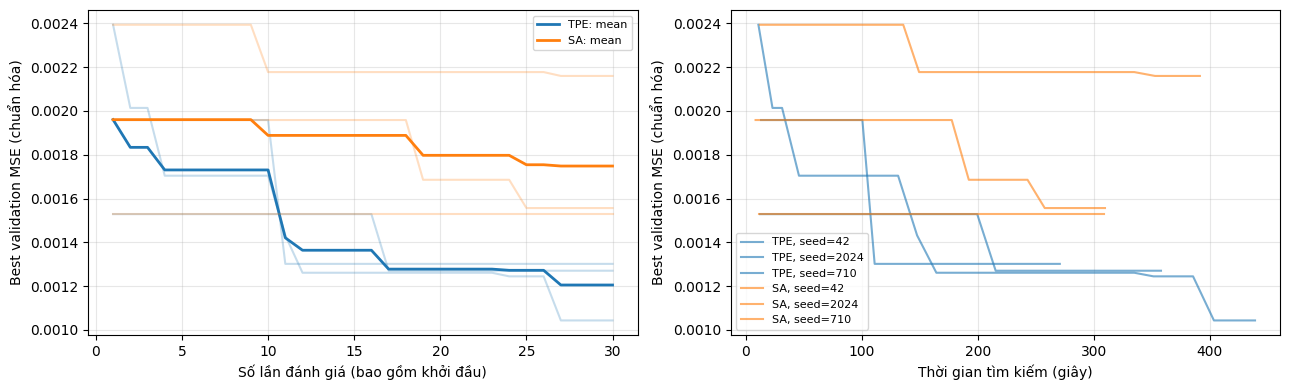

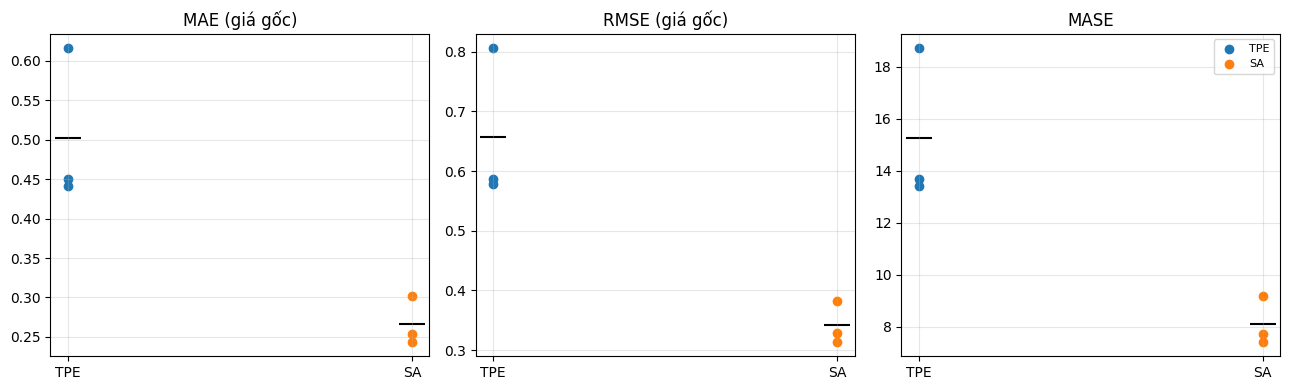

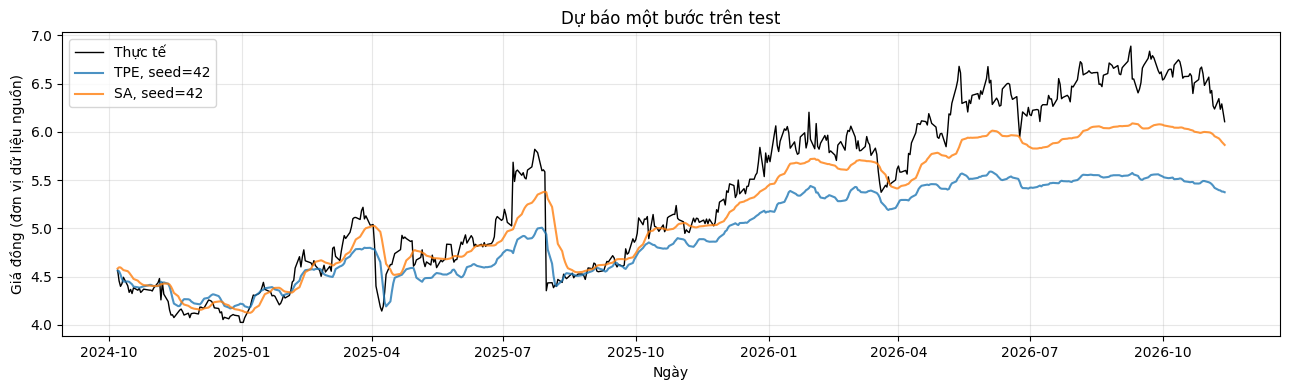

Biểu đồ ratio=0.9


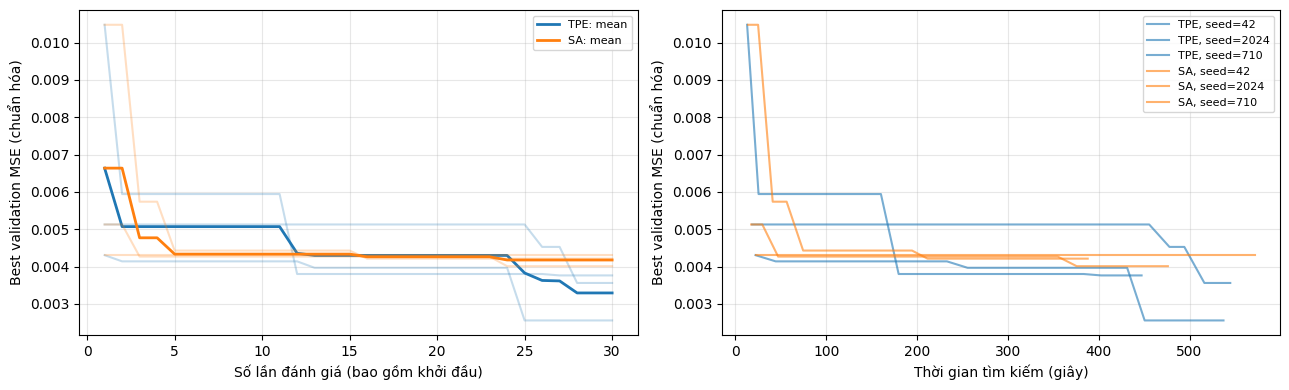

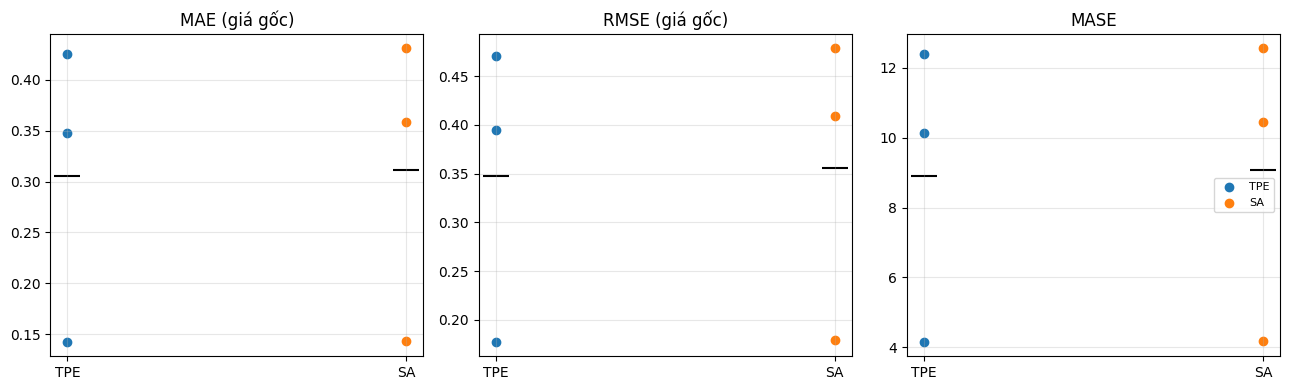

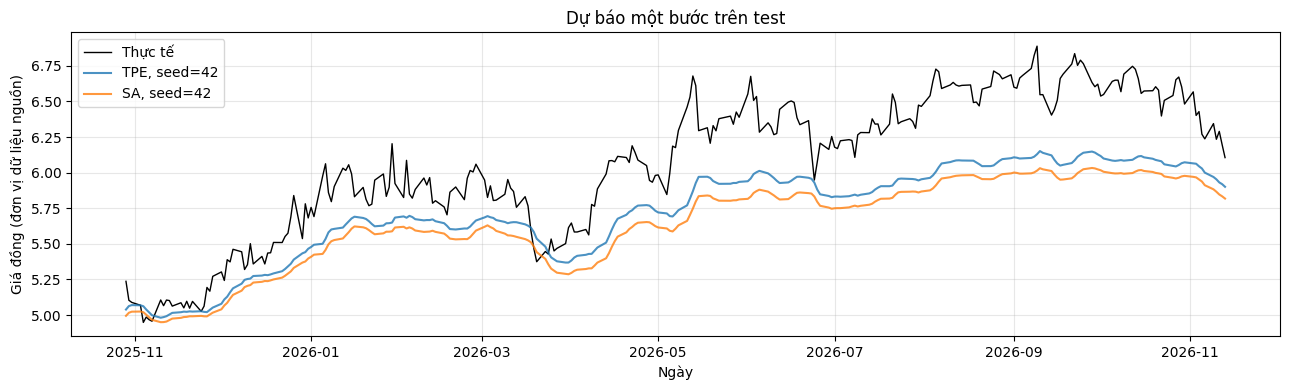

Biểu đồ ratio=0.925


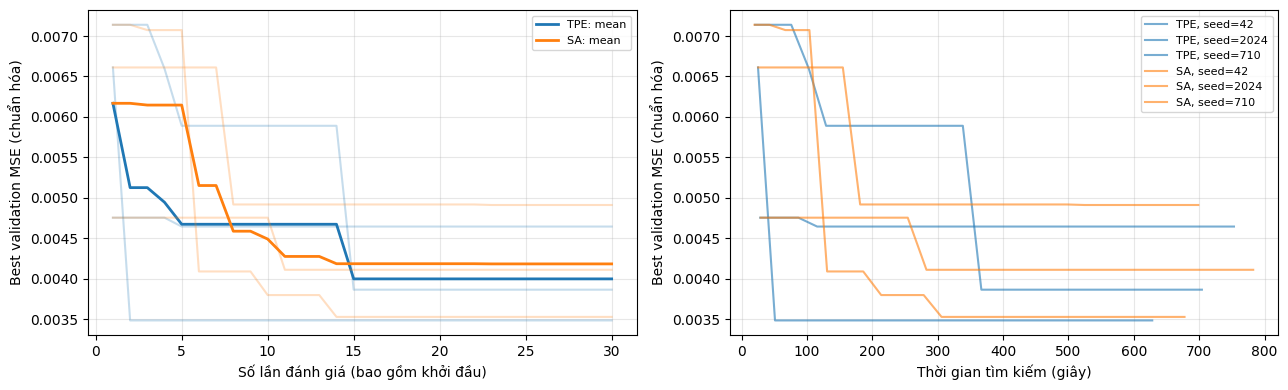

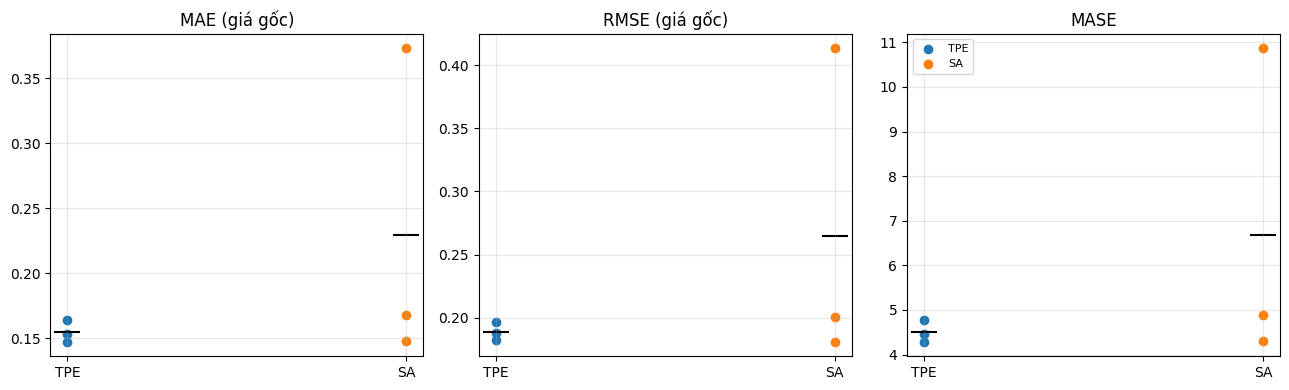

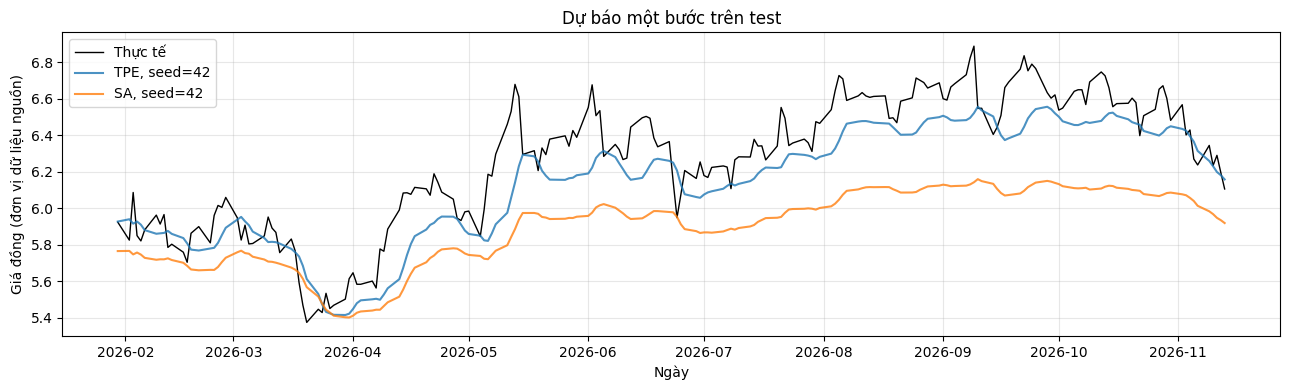

Biểu đồ ratio=0.95


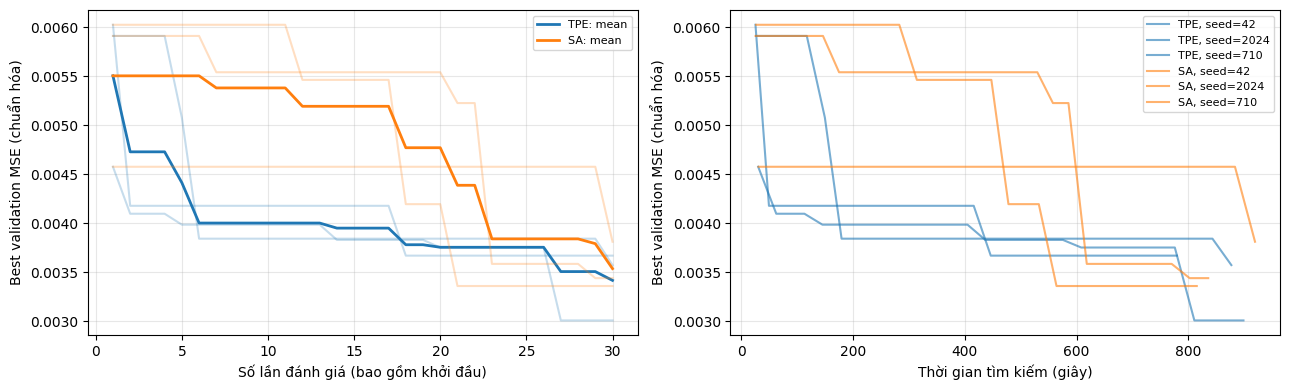

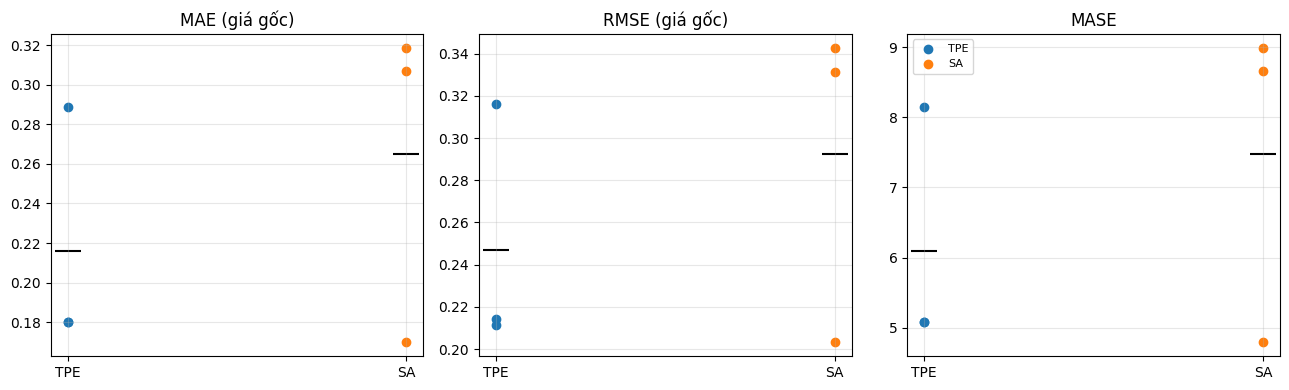

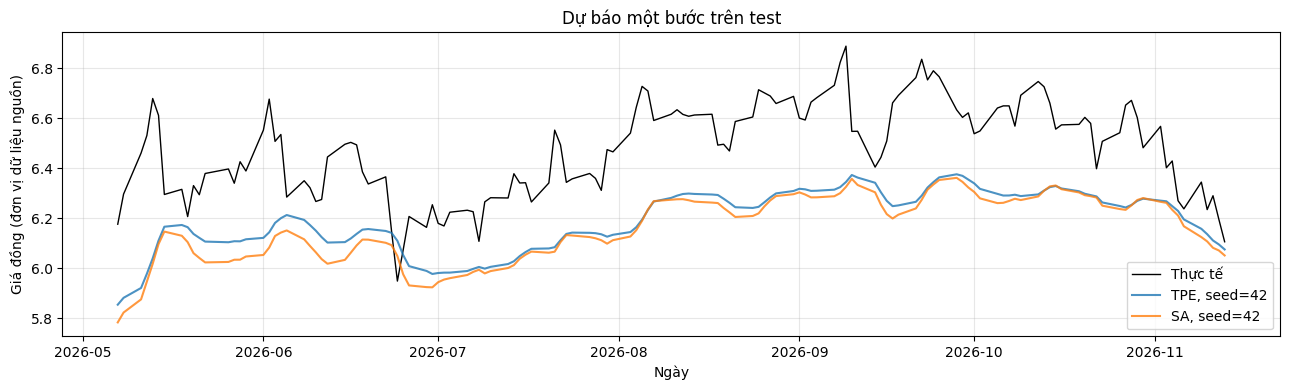

In [12]:
def plot_one_ratio(ratio):
    RUN_DIR=split_contexts[ratio]["folder"]
    trials_df=all_trials.loc[all_trials.ratio==ratio].copy()
    results_df=all_results.loc[all_results.ratio==ratio].copy()
    predictions_df=all_predictions.loc[all_predictions.ratio==ratio].copy()
    D=prepare_data(df,ratio,split_contexts[ratio]["features"],include_test=True)
    fig, axes = plt.subplots(1, 2, figsize=(13,4))
    colors = {'TPE':'tab:blue','SA':'tab:orange'}
    for method in ['TPE','SA']:
        matrix = []
        for seed in SEEDS:
            g = trials_df[(trials_df.method==method)&(trials_df.seed==seed)].sort_values('trial')
            best_so_far = g.val_mse.cummin().to_numpy()
            matrix.append(best_so_far)
            axes[0].plot(g.trial, best_so_far, color=colors[method], alpha=.25)
            axes[1].plot(g.elapsed_seconds, best_so_far, color=colors[method], alpha=.6,
                         label=f'{method}, seed={seed}')
        matrix = np.asarray(matrix)
        # Failed trials có inf; chỉ vẽ mean hữu hạn khi mọi seed có kết quả hữu hạn.
        valid_columns = np.all(np.isfinite(matrix), axis=0)
        axes[0].plot(np.arange(1,N_TRIALS+1)[valid_columns], matrix[:,valid_columns].mean(axis=0),
                     color=colors[method], linewidth=2, label=f'{method}: mean')
    axes[0].set_xlabel('Số lần đánh giá (bao gồm khởi đầu)')
    axes[1].set_xlabel('Thời gian tìm kiếm (giây)')
    for ax in axes:
        ax.set_ylabel('Best validation MSE (chuẩn hóa)')
        ax.grid(alpha=.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RUN_DIR/'convergence.png', dpi=160)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(13,4))
    for ax, metric in zip(axes, ['MAE','RMSE','MASE']):
        for x, method in enumerate(['TPE','SA']):
            vals = results_df.loc[results_df.method==method, metric].to_numpy()
            ax.scatter(np.full(len(vals), x), vals, color=colors[method], label=method)
            ax.scatter(x, vals.mean(), marker='_', s=350, color='black')
        ax.set_xticks([0,1], ['TPE','SA'])
        ax.set_title(metric + (' (giá gốc)' if metric!='MASE' else ''))
        ax.grid(alpha=.3)
    axes[-1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(RUN_DIR/'test_metrics.png', dpi=160)
    plt.show()

    # Seed đầu tiên được định trước để minh họa, không chọn seed đẹp nhất theo test.
    fig, ax = plt.subplots(figsize=(13,4))
    ax.plot(D['test_dates'], D['y_test_original'], color='black', label='Thực tế', linewidth=1)
    for method in ['TPE','SA']:
        p = predictions_df[(predictions_df.method==method)&(predictions_df.seed==SEEDS[0])]
        ax.plot(p.Date, p.Predicted, label=f'{method}, seed={SEEDS[0]}', alpha=.8)
    ax.set(xlabel='Ngày', ylabel='Giá đồng (đơn vị dữ liệu nguồn)', title='Dự báo một bước trên test')
    ax.legend()
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(RUN_DIR/'test_predictions.png', dpi=160)
    plt.show()

all_trials=trials_df; all_results=results_df; all_predictions=predictions_df
for ratio in RATIOS:
    print(f"Biểu đồ ratio={ratio}")
    plot_one_ratio(ratio)


## 7. Đọc kết quả

`data_split_summary.csv` ghi số mẫu và ngày đầu/cuối từng tập theo tỷ lệ. Mỗi thư mục `ratio_*` có bảng Spearman và biến được chọn riêng, checkpoint SA/TPE và các hình. `metrics_by_run.csv`, `summary_mean_std.csv`, `paired_differences.csv`, `test_predictions.csv` ở thư mục gốc đều có ratio để tránh trộn cách chia. `all_trials.csv` và `selected_configs.json` lưu quyết định tuning trước khi predict test.

Chỉ so sánh SA/TPE trên cùng ratio; xem sai số trung bình, sample std, thời gian và epoch thực tế. Không xem bốn khoảng test chồng lấn là bốn lần kiểm định độc lập. Report có 4×3×2×30=720 lần huấn luyện trial; quick có 4×1×2×4=32 trial. Chỉ giữ model trial thắng, không huấn luyện thêm sau tuning. Report vì vậy tốn khoảng bốn lần ngân sách tìm kiếm so với bản một ratio cũ.

Đã kiểm tra logic với CSV thật và mục tiêu giả lập, chưa chạy TensorFlow end-to-end trên Kaggle. Kiểm tra quick trước; không dùng kết quả quick để kết luận nghiên cứu.

`input_history_audit.csv` ghi ngày đầu/cuối của input và ngày target để kiểm tra quan hệ quá khứ → tương lai. `example_validation_input_22_sessions.csv` trong từng ratio chứa một mẫu đầu vào gồm 22 phiên, có Copper quá khứ; không chứa giá Copper của ngày target.


In [13]:
# Gói kết quả của lần chạy hiện tại để tải từ Kaggle.
import shutil
from IPython.display import FileLink
zip_path = shutil.make_archive(str(ROOT_RUN_DIR), 'zip', root_dir=ROOT_RUN_DIR)
print('Kết quả:', ROOT_RUN_DIR)
print('ZIP:', zip_path)
display(FileLink(zip_path))

Kết quả: /kaggle/working/results_tpe_sa_copper_history_v20/20261118T121724200339Z_report
ZIP: /kaggle/working/results_tpe_sa_copper_history_v20/20261118T121724200339Z_report.zip


/kaggle/working/results_tpe_sa_copper_history_v20/20261118T121724200339Z_report.zip